In [49]:
# Import all packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [50]:
# Load excel file
file = "LETFs + SPY dataset.xlsx"
xls = pd.ExcelFile(file)
xls.sheet_names

['UPRO US', 'SPXU CN', '3USL LN', '2239 JP', '7200 HK', 'SPY US']

In [51]:
# Check the file
df_test = pd.read_excel(file, sheet_name="UPRO US")

print(df_test.head())
print(df_test.columns)

       Dates    Open    High     Low   Close    Volume     TRI    r_LETF
0 2009-06-25  1.1263  1.2104  1.1263  1.2056   2575440  1.2056       NaN
1 2009-06-26  1.1953  1.2131  1.1774  1.1993  13105008  1.1993 -0.005239
2 2009-06-29  1.2083  1.2361  1.1914  1.2333   8691984  1.2333  0.027955
3 2009-06-30  1.2333  1.2433  1.1764  1.2039  17128368  1.2039 -0.024127
4 2009-07-01  1.2185  1.2529  1.2136  1.2168  12039552  1.2168  0.010658
Index(['Dates', 'Open', 'High', 'Low', 'Close', 'Volume', 'TRI', 'r_LETF'], dtype='object')


In [52]:
# Define 5 LETFs and benchmark
etfs = ["UPRO US", "SPXU CN", "3USL LN", "2239 JP", "7200 HK"]
benchmark = "SPY US"

# Load LETF sheets
def load_letf(sheet):
    df = pd.read_excel(file, sheet_name=sheet)
    df = df.rename(columns={"Dates": "date", "r_LETF": "r_letf"})
    df["date"] = pd.to_datetime(df["date"])
    df["etf"] = sheet
    return df[["date", "etf", "r_letf"]]

all_etfs = pd.concat([load_letf(e) for e in etfs], ignore_index=True)
all_etfs.head()

,date,etf,r_letf
0,2009-06-25,UPRO US,NaN
1,2009-06-26,UPRO US,-0.005239
2,2009-06-29,UPRO US,0.027955
3,2009-06-30,UPRO US,-0.024127
4,2009-07-01,UPRO US,0.010658


In [53]:
# Load SPY benchmark
spy = pd.read_excel(file, sheet_name=benchmark)

spy = spy.rename(columns={
    "Dates": "date",
    "r_SPY": "r_spy"
})

spy["date"] = pd.to_datetime(spy["date"])

spy = spy[["date", "r_spy"]]

# Merge with ETF returns
data = all_etfs.merge(spy, on="date", how="inner")

# Remove missing values
data = data.dropna()

data.head()

,date,etf,r_letf,r_spy
1,2009-06-26,UPRO US,-0.005239,-0.002609
2,2009-06-29,UPRO US,0.027955,0.009321
3,2009-06-30,UPRO US,-0.024127,-0.008124
4,2009-07-01,UPRO US,0.010658,0.004124
5,2009-07-02,UPRO US,-0.086115,-0.027673


In [54]:
# Momentum Strategy 
data = data.sort_values(["etf", "date"])

# 20-day momentum signal
lookback = 20

# Past 20-day cumulative return
data["mom"] = (data.groupby("etf")["r_letf"].transform(lambda x: np.exp(x.rolling(lookback).sum()) - 1))

# Trading signal (1 if momentum positive, 0 otherwise)
data["signal"] = np.where(data["mom"] > 0, 1, 0)

# Use yesterday's signal to trade today
data["signal_lag"] = data.groupby("etf")["signal"].shift(1)

# Calculate strategy return
data["r_strat"] = data["signal_lag"] * data["r_letf"]

# Remove missing values
data = data.dropna()

# Check the values
data[["date", "etf", "r_letf", "mom", "signal_lag", "r_strat"]].head(10)

,date,etf,r_letf,mom,signal_lag,r_strat
12236,2023-04-14,2239 JP,0.026437,0.081752,0.0,0.000000
12237,2023-04-17,2239 JP,0.000899,0.111389,1.0,0.000899
12238,2023-04-18,2239 JP,0.002245,0.113886,1.0,0.002245
12239,2023-04-19,2239 JP,-0.001795,0.071738,1.0,-0.001795
12240,2023-04-20,2239 JP,-0.002699,0.082927,1.0,-0.002699
12241,2023-04-21,2239 JP,-0.004967,0.093023,1.0,-0.004967
12242,2023-04-24,2239 JP,-0.005447,0.061353,1.0,-0.005447
12243,2023-04-25,2239 JP,0.002273,0.067895,1.0,0.002273
12244,2023-04-26,2239 JP,-0.018795,0.045983,1.0,-0.018795
12245,2023-04-27,2239 JP,-0.010700,0.017127,1.0,-0.010700


In [55]:
data.groupby("etf")[["r_letf", "mom", "signal_lag", "r_strat"]].describe()

r_letf                                                              \
          count      mean       std       min       25%       50%       75%   
etf                                                                           
2239 JP   736.0  0.000962  0.020765 -0.203845 -0.006759  0.000583  0.009690   
3USL LN  3412.0  0.000962  0.028979 -0.309421 -0.009881  0.001191  0.014421   
7200 HK  2304.0 -0.000077  0.028259 -0.320307 -0.014663  0.000000  0.014783   
SPXU CN  4583.0  0.000537  0.024307 -0.269395 -0.007524  0.000916  0.011227   
UPRO US  4161.0  0.001077  0.032748 -0.429952 -0.011176  0.002164  0.016999   

                      mom            ... signal_lag      r_strat            \
              max   count      mean  ...        75%  max   count      mean   
etf                                  ...                                     
2239 JP  0.198186   736.0  0.023709  ...        1.0  1.0   736.0  0.000547   
3USL LN  0.222206  3412.0  0.027998  ...        1.0  1.0  3412.0  0.000616   
7200 HK  0.157876  2304.0  0.005592  ...        1.0  1.0  2304.0 -0.000032   
SPXU CN  0.198276  4583.0  0.015051  ...        1.0  1.0  4583.0  0.000427   
UPRO US  0.246587  4161.0  0.031239  ...        1.0  1.0  4161.0  0.000645   

                                                                
              std       min       25%  50%       75%       max  
etf                                                             
2239 JP  0.012241 -0.060829 -0.002273  0.0  0.005335  0.056718  
3USL LN  0.018170 -0.142248 -0.001839  0.0  0.006852  0.106626  
7200 HK  0.017876 -0.210640  0.000000  0.0  0.000000  0.116257  
SPXU CN  0.013301 -0.127246 -0.001239  0.0  0.004303  0.100782  
UPRO US  0.019425 -0.192005 -0.003061  0.0  0.007244  0.152198  

[5 rows x 32 columns]

In [56]:
# Descriptive statistics 
desc = data.groupby("etf")["r_strat"].agg(["mean", "std", "count"])
desc["sharpe_daily"] = desc["mean"] / desc["std"]
desc["sharpe_annual"] = desc["sharpe_daily"] * np.sqrt(252)

desc

,mean,std,count,sharpe_daily,sharpe_annual
etf,,,,,
2239 JP,0.000547,0.012241,736,0.044675,0.709188
3USL LN,0.000616,0.018170,3412,0.033901,0.538167
7200 HK,-0.000032,0.017876,2304,-0.001815,-0.028811
SPXU CN,0.000427,0.013301,4583,0.032088,0.509375
UPRO US,0.000645,0.019425,4161,0.033189,0.526859


In [57]:
# Sorting values + export to excel 
desc = desc.sort_values("mean", ascending=False)
desc.to_excel("descriptive_statistics.xlsx")

In [58]:
# Regression 1: alpha and beta for each ETF

country_map = {
    "UPRO US": "US",
    "SPXU CN": "Canada",
    "3USL LN": "Europe",
    "2239 JP": "Japan",
    "7200 HK": "Hong Kong"
}
data["country"] = data["etf"].map(country_map)

reg_results = []

for e in data["etf"].unique():
    temp = data[data["etf"] == e]
    
    y = temp["r_strat"]
    x = temp["r_spy"]
    n = len(y)
    
    beta, alpha = np.polyfit(x, y, 1)
    
    y_hat = alpha + beta * x
    ss_res = ((y - y_hat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot

# Standard error of regression
    s = np.sqrt(ss_res / (n - 2))
    
# Standard error of alpha
    se_alpha = s * np.sqrt(1/n + (x.mean()**2) / ((x - x.mean())**2).sum())
    t_alpha = alpha / se_alpha
    
    reg_results.append([e, alpha, alpha * 252, t_alpha, beta, r2])

reg_table = pd.DataFrame(reg_results, columns=["ETF", "Alpha daily", "Alpha annual", "t-stat", "Beta", "R-squared"])

reg_table["Country"] = reg_table["ETF"].map(country_map)

reg_table = reg_table[["ETF", "Country", "Alpha daily", "Alpha annual", "t-stat", "Beta", "R-squared"]]

reg_table.round(5)

,ETF,Country,Alpha daily,Alpha annual,t-stat,Beta,R-squared
0,2239 JP,Japan,0.00047,0.11933,1.04836,0.09836,0.00561
1,3USL LN,Europe,0.00030,0.07594,1.03176,0.60294,0.12088
2,7200 HK,Hong Kong,-0.00011,-0.02826,-0.30224,0.15092,0.00954
3,SPXU CN,Canada,0.00017,0.04387,1.03592,0.56036,0.26947
4,UPRO US,US,0.00006,0.01625,0.26647,1.07094,0.35587


In [59]:
# Export to excel 
reg_table.to_excel("regression_alpha_beta_by_etf.xlsx", index=False)

In [60]:
# Comparing performance by country

country_results = data.groupby("country")["r_strat"].agg(["mean", "std", "count"])

country_results["mean"] = country_results["mean"] * 100
country_results["std"] = country_results["std"] * 100

country_results.round(4)

,mean,std,count
country,,,
Canada,0.0427,1.3301,4583
Europe,0.0616,1.8170,3412
Hong Kong,-0.0032,1.7876,2304
Japan,0.0547,1.2241,736
US,0.0645,1.9425,4161


In [61]:
country_results.to_excel("country_performance_results.xlsx")

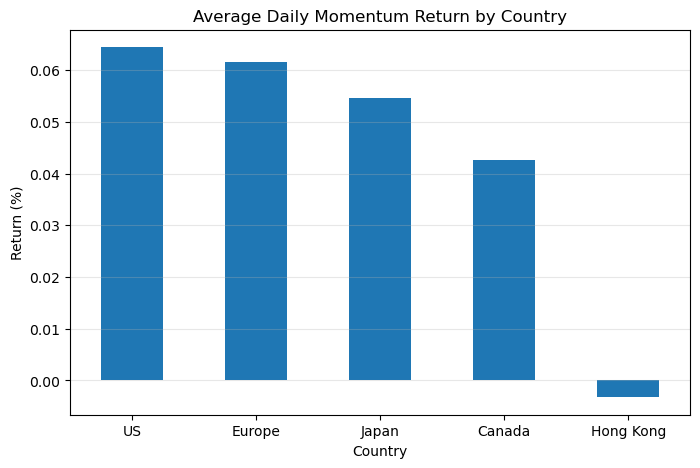

In [62]:
import matplotlib.pyplot as plt

# Average daily return by country (converted to %)
country_returns = (data.groupby("country")["r_strat"].mean().sort_values(ascending=False) * 100)

# Create bar chart
plt.figure(figsize=(8, 5))
country_returns.plot(kind="bar")

# Labels and title
plt.title("Average Daily Momentum Return by Country")
plt.ylabel("Return (%)")
plt.xlabel("Country")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

# Show chart
plt.show()

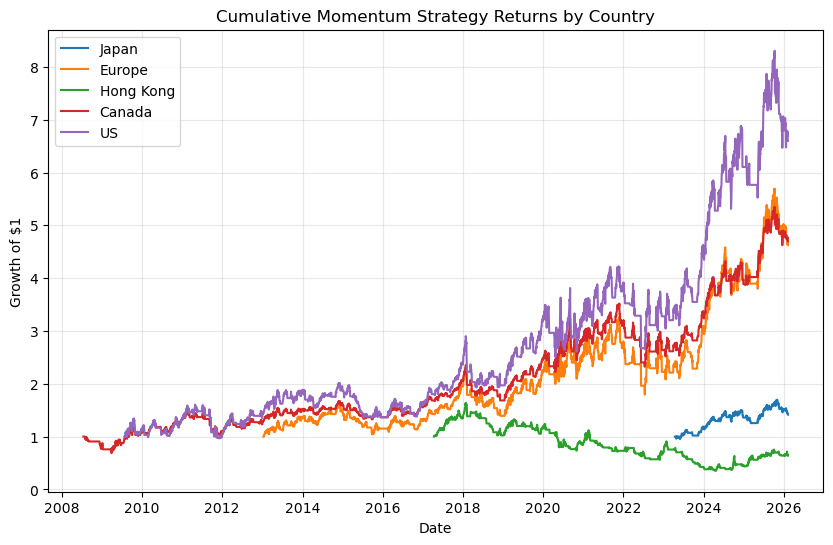

In [63]:
# Cumulative momentum strategy returns by country

plt.figure(figsize=(10, 6))

for country in data["country"].unique():
    
    # Average daily strategy return for this country
    temp = data[data["country"] == country]
    temp = temp.groupby("date")["r_strat"].mean()
    temp = temp.sort_index()
    
    # Compute cumulative return manually
    cumulative = [1]   # Start with $1 invested
    
    for r in temp:
        cumulative.append(cumulative[-1] * (1 + r))
    
    # Remove the first initial value
    cumulative = cumulative[1:]
    
# Plot
    plt.plot(temp.index, cumulative, label=country)
plt.title("Cumulative Momentum Strategy Returns by Country")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()